<a href="https://colab.research.google.com/github/ethereal-arko/Perkinson-s_Disease_Prediction/blob/main/Parkinson's_Disease_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Parkinson's Disease Prediction Using Machine Learning

## 1. Project Overview

Parkinson's disease is a progressive neurological disorder that affects movement and may also influence speech and voice characteristics. Certain measurable voice features can contain patterns associated with the disease.

In this project, we use supervised machine learning to build a binary classification model based on voice measurement data. A Support Vector Machine (SVM) classifier is trained to distinguish between two classes: healthy/control records and Parkinson's-positive records.

### Objectives

- Explore and understand the voice measurement dataset.
- Identify data quality issues and investigate class imbalance.
- Perform exploratory data analysis (EDA).
- Prepare numerical features for machine learning.
- Train a Support Vector Machine classifier.
- Evaluate the model using appropriate classification metrics.
- Build a prediction function for new input data.

### Dataset Description

The dataset contains voice measurement records and a target column named `status`.

- `name`: recording identifier.
- Numerical measurement columns: voice-related features used as model inputs.
- `status`: target variable, where `0` represents the healthy/control class and `1` represents the Parkinson's-positive class.

The `name` column will not be used as a predictive feature because it is an identifier rather than a voice measurement.

### Model Overview

We will initially investigate a linear Support Vector Machine (SVM). SVM is a supervised learning algorithm that learns a decision boundary to separate classes.

Because SVM is sensitive to feature scales, standardization will be considered during preprocessing. Model performance will be evaluated on data not used for model fitting.

### Important Limitation

This project is intended for educational and research practice. A model prediction is not a medical diagnosis and must not replace assessment by a qualified healthcare professional.



## 2. Import Libraries and Load the Dataset

In this section, we import the Python libraries required for data manipulation, numerical operations, visualization, preprocessing, model training, and evaluation.

We then load the CSV dataset into a pandas DataFrame.

A DataFrame organizes tabular data into rows and columns, making it easier to inspect and prepare the dataset for machine learning.


In [2]:

# Import libraries for data handling
import numpy as np
import pandas as pd

# Import libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import tools for data splitting and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Import the SVM classifier
from sklearn.svm import SVC

# Import evaluation metrics
from sklearn.metrics import accuracy_score

# Set a consistent visualization style
sns.set_theme(style="whitegrid")


# Load the dataset directly from GitHub
DATASET_URL = (
    "https://raw.githubusercontent.com/"
    "ethereal-arko/Perkinson-s_Disease_Prediction/"
    "main/parkinsons.csv"
)

parkinsons_data = pd.read_csv(DATASET_URL)

print("Dataset loaded successfully!")



Dataset loaded successfully!



## 3. Initial Dataset Inspection

Before performing any analysis or training a model, we need to understand the dataset's structure and quality.

This initial inspection includes:

- Viewing the first few records.
- Checking the number of rows and columns.
- Inspecting column names and data types.
- Detecting missing values and exact duplicate rows.
- Examining the distribution of the target variable.

These checks help identify potential data quality issues and guide the next preprocessing steps.


In [ ]:

# Display the first five records
display(parkinsons_data.head())

# Check dataset dimensions
print("Dataset shape:", parkinsons_data.shape)

# Inspect column names, data types, and non-null counts
print("\nDataset information:")
parkinsons_data.info()

# Check missing values in each column
print("\nMissing values per column:")
print(parkinsons_data.isnull().sum())

# Count exact duplicate rows
print("\nNumber of duplicate rows:",
      parkinsons_data.duplicated().sum())

# Examine target class counts
print("\nTarget class counts:")
print(parkinsons_data['status'].value_counts().sort_index())

# Examine target class percentages
print("\nTarget class percentages:")
print(
    (parkinsons_data['status'].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)


,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,...,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,...,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,...,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,...,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,...,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


Dataset shape: (195, 24)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              195 non-null    object 
 1   MDVP:Fo(Hz)       195 non-null    float64
 2   MDVP:Fhi(Hz)      195 non-null    float64
 3   MDVP:Flo(Hz)      195 non-null    float64
 4   MDVP:Jitter(%)    195 non-null    float64
 5   MDVP:Jitter(Abs)  195 non-null    float64
 6   MDVP:RAP          195 non-null    float64
 7   MDVP:PPQ          195 non-null    float64
 8   Jitter:DDP        195 non-null    float64
 9   MDVP:Shimmer      195 non-null    float64
 10  MDVP:Shimmer(dB)  195 non-null    float64
 11  Shimmer:APQ3      195 non-null    float64
 12  Shimmer:APQ5      195 non-null    float64
 13  MDVP:APQ          195 non-null    float64
 14  Shimmer:DDA       195 non-null    float64
 15  NHR               195 non-null    float64
 1


### Findings

The initial inspection produced the following results:

- **Dataset size:** 195 records and 24 columns.
- **Data types:** One object column (`name`), one integer target column (`status`), and 22 floating-point measurement columns.
- **Missing values:** No missing values were detected.
- **Exact duplicate rows:** No exact duplicate rows were detected.
- **Target distribution:** 147 records belong to class `1` (75.38%), while 48 records belong to class `0` (24.62%).

The target classes are imbalanced, with substantially more positive records than control records.

A classifier that predicts class `1` for every record would achieve approximately 75.38% accuracy on this dataset without learning to identify the control class. Therefore, accuracy alone will not be sufficient to assess model performance.

Although no exact duplicate rows were found, the dataset may contain multiple recordings associated with the same participant. We will investigate the recording identifiers before deciding how to split the data for evaluation.



## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the distribution of individual features and how their values vary across target classes.

In this section, we will:

1. Visualize the distribution of the target variable.
2. Examine the distributions of selected voice measurement features.
3. Compare selected feature distributions between the two classes using boxplots.

These visualizations can reveal patterns, skewness, spread, and potential differences between classes. However, visual differences alone do not establish causation or confirm diagnostic usefulness.


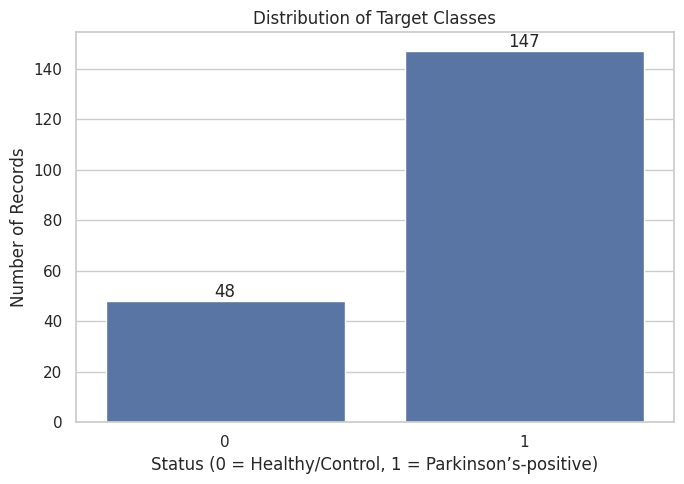

In [ ]:

# 4.1 Visualize the target class distribution

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=parkinsons_data,
    x='status'
)

ax.set_title('Distribution of Target Classes')
ax.set_xlabel('Status (0 = Healthy/Control, 1 = Parkinson’s-positive)')
ax.set_ylabel('Number of Records')

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()


In [ ]:

# Numerical summary of selected features
selected_features = [
    'MDVP:Fo(Hz)',
    'MDVP:Jitter(%)',
    'MDVP:Shimmer',
    'HNR',
    'PPE'
]

print("Feature statistics by target class:\n")

for feature in selected_features:
    print(f"\nFeature: {feature}")

    display(
        parkinsons_data.groupby('status')[feature]
        .agg(['mean', 'median', 'std', 'min', 'max'])
        .round(4)
    )


Feature statistics by target class:


Feature: MDVP:Fo(Hz)


,mean,median,std,min,max
status,,,,,
0,181.9378,198.996,52.7311,110.739,260.105
1,145.1808,145.174,32.3480,88.333,223.361



Feature: MDVP:Jitter(%)


,mean,median,std,min,max
status,,,,,
0,0.0039,0.0034,0.0021,0.0018,0.0136
1,0.0070,0.0054,0.0052,0.0017,0.0332



Feature: MDVP:Shimmer


,mean,median,std,min,max
status,,,,,
0,0.0176,0.0167,0.0055,0.0095,0.0409
1,0.0337,0.0284,0.0200,0.0102,0.1191



Feature: HNR


,mean,median,std,min,max
status,,,,,
0,24.6787,24.997,3.4345,17.883,33.047
1,20.9740,21.414,4.3391,8.441,29.928



Feature: PPE


,mean,median,std,min,max
status,,,,,
0,0.1230,0.1151,0.0448,0.0445,0.2524
1,0.2338,0.2227,0.0843,0.0932,0.5274


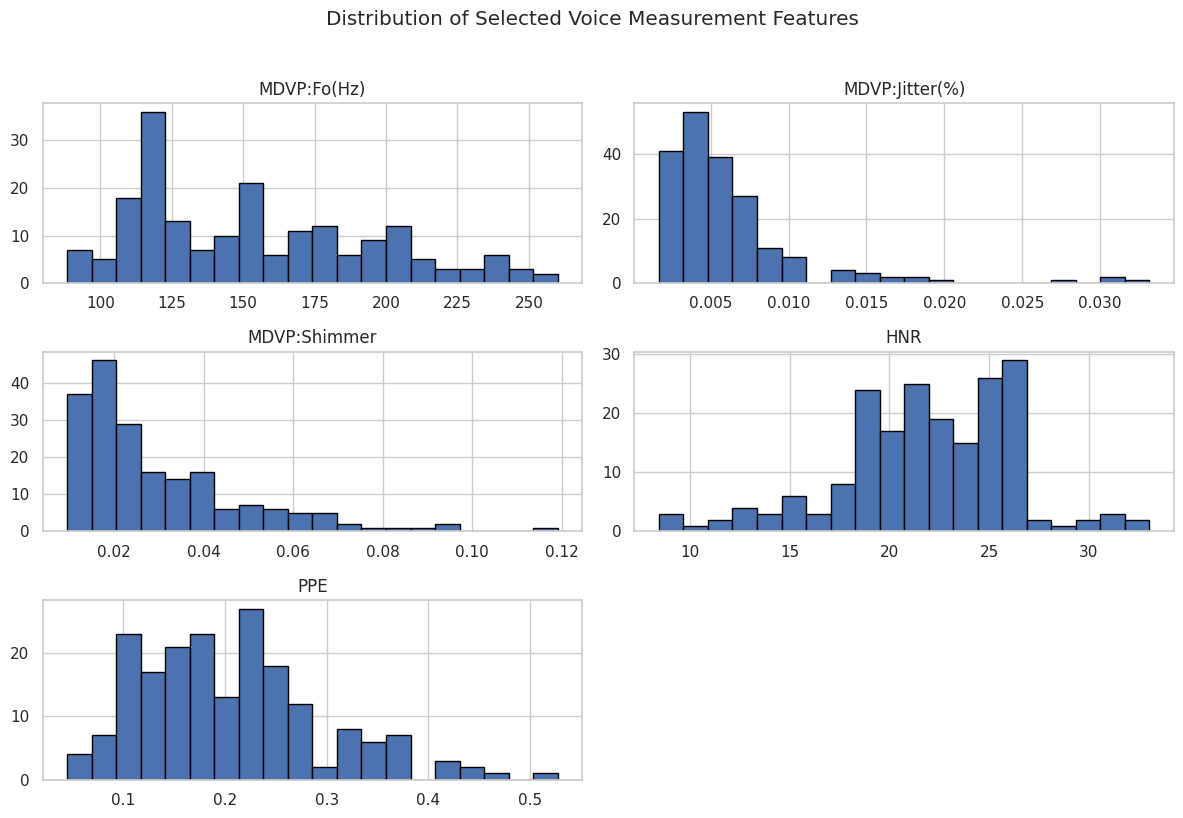

In [ ]:

# 4.2 Examine distributions of selected numerical features

selected_features = [
    'MDVP:Fo(Hz)',
    'MDVP:Jitter(%)',
    'MDVP:Shimmer',
    'HNR',
    'PPE'
]

parkinsons_data[selected_features].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor='black'
)

plt.suptitle(
    'Distribution of Selected Voice Measurement Features',
    y=1.02
)

plt.tight_layout()
plt.show()


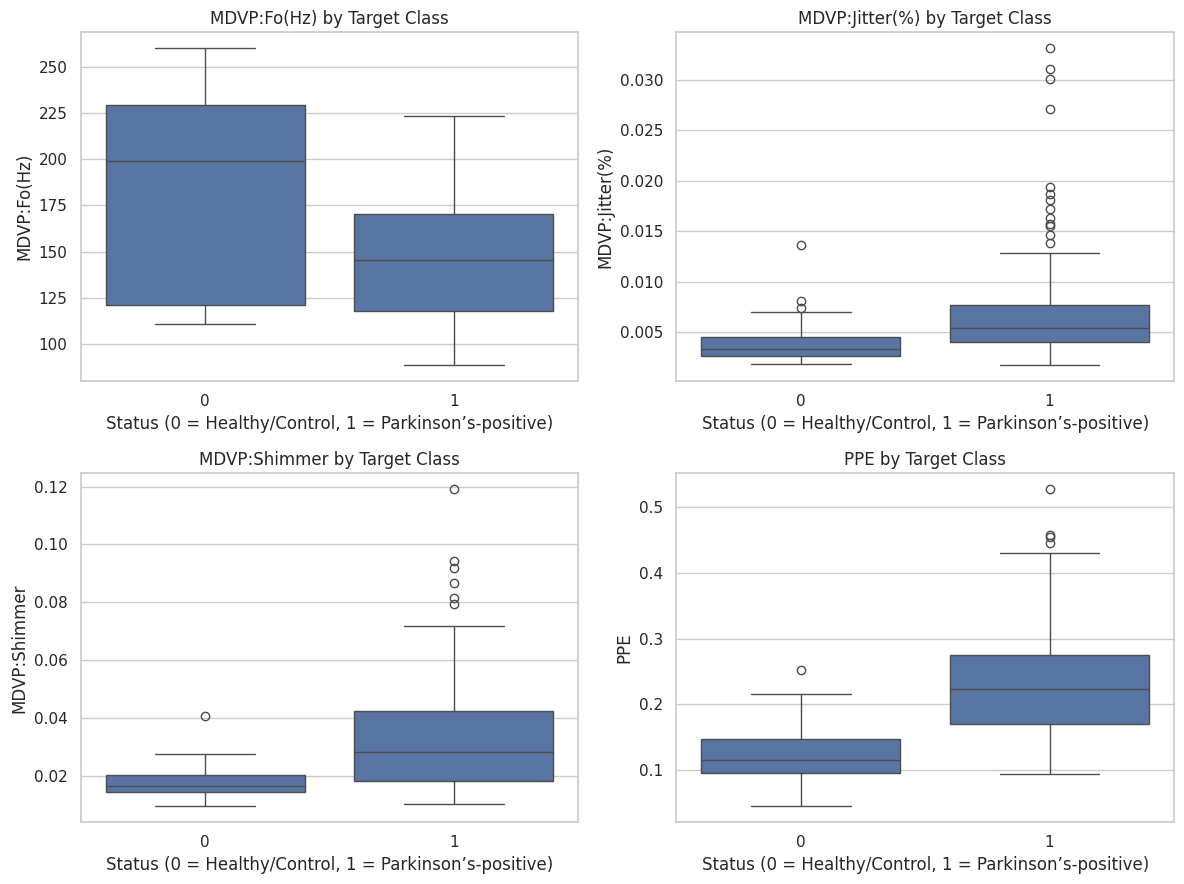

In [ ]:

# 4.3 Compare selected features across target classes

features_to_compare = [
    'MDVP:Fo(Hz)',
    'MDVP:Jitter(%)',
    'MDVP:Shimmer',
    'PPE'
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, feature in zip(axes.flatten(), features_to_compare):
    sns.boxplot(
        data=parkinsons_data,
        x='status',
        y=feature,
        ax=ax
    )

    ax.set_title(f'{feature} by Target Class')
    ax.set_xlabel('Status (0 = Healthy/Control, 1 = Parkinson’s-positive)')

plt.tight_layout()
plt.show()



### 4.5 Interpretation of Selected Features

The numerical summaries show differences between the healthy/control and Parkinson's-positive classes for the selected voice measurements.

- **MDVP:Fo(Hz):** The mean fundamental frequency is lower in the Parkinson's-positive class (145.1808 Hz) than in the control class (181.9378 Hz).
- **MDVP:Jitter(%):** The Parkinson's-positive class has a higher mean jitter value (0.0070 versus 0.0039).
- **MDVP:Shimmer:** The mean shimmer value is higher in the Parkinson's-positive class (0.0337 versus 0.0176).
- **HNR:** The mean harmonic-to-noise ratio is lower in the Parkinson's-positive class (20.9740 versus 24.6787).
- **PPE:** The mean value is higher in the Parkinson's-positive class (0.2338 versus 0.1230).

These differences suggest that the selected features may contain information useful for distinguishing the two classes. However, their distributions overlap, and these observations do not establish causation or provide diagnostic thresholds.

The next step is to investigate whether multiple records belong to the same participant. This matters because a random row-wise split may place recordings from one participant in both the training and testing sets, potentially producing an overly optimistic evaluation.



## 5. Investigating Participant Identifiers

The `name` column contains recording identifiers such as `phon_R01_S01_1`. These identifiers appear to contain multiple components, potentially including a participant identifier.

Before splitting the dataset, we will inspect the identifier structure and determine whether records can be grouped by participant. The identifier itself will not be used as a model feature.

If participant-level grouping can be established reliably, we will consider a group-based train-test split so that records from the same participant do not appear in both sets.


In [ ]:

# Inspect the recording identifier structure
print("First 10 recording identifiers:")
print(parkinsons_data['name'].head(10).to_list())

# Check identifier uniqueness
print("\nTotal records:", len(parkinsons_data))
print("Unique recording identifiers:", parkinsons_data['name'].nunique())

# Extract potential subject IDs such as S01, S02, etc.
parkinsons_data['subject_id'] = (
    parkinsons_data['name'].str.extract(r'(S\d+)', expand=False)
)

print("\nNumber of missing extracted subject IDs:",
      parkinsons_data['subject_id'].isna().sum())

print("Number of unique extracted subject IDs:",
      parkinsons_data['subject_id'].nunique())

# Inspect how many records are associated with each potential subject
print("\nRecords per potential subject:")
display(
    parkinsons_data['subject_id']
    .value_counts()
    .sort_index()
    .rename_axis('subject_id')
    .to_frame('record_count')
)

# Check whether each potential subject has one consistent target label
subject_label_counts = (
    parkinsons_data.groupby('subject_id')['status'].nunique()
)

print("\nSubjects with more than one target label:",
      (subject_label_counts > 1).sum())


First 10 recording identifiers:
['phon_R01_S01_1', 'phon_R01_S01_2', 'phon_R01_S01_3', 'phon_R01_S01_4', 'phon_R01_S01_5', 'phon_R01_S01_6', 'phon_R01_S02_1', 'phon_R01_S02_2', 'phon_R01_S02_3', 'phon_R01_S02_4']

Total records: 195
Unique recording identifiers: 195

Number of missing extracted subject IDs: 0
Number of unique extracted subject IDs: 32

Records per potential subject:


,record_count
subject_id,
S01,6
S02,6
S04,6
S05,6
S06,6
S07,6
S08,6
S10,6
S13,6



Subjects with more than one target label: 0



## 6. Feature Selection and Subject-Wise Train-Test Split

### 6.1 Separating Features and Target

The `status` column is the target variable. The `name` column is a recording identifier, and `subject_id` is used only to identify participant groups.

Therefore, neither identifier will be included as a predictive feature.

### 6.2 Subject-Wise Data Splitting

Multiple recordings may belong to the same participant. A conventional random row-wise split could place recordings from the same participant in both the training and testing sets.

To reduce this risk, we will use `StratifiedGroupKFold`. This method attempts to preserve class proportions while keeping all records from a participant in the same fold.

We will use one fold as the holdout test set and verify that no participant appears in both sets. Since this dataset contains only 32 potential participant groups, the resulting performance estimate may have considerable uncertainty.


In [ ]:

from sklearn.model_selection import StratifiedGroupKFold

# Separate input features and target
X = parkinsons_data.drop(
    columns=['name', 'status', 'subject_id']
)

y = parkinsons_data['status']
groups = parkinsons_data['subject_id']

print("Number of input features:", X.shape[1])
print("Total records:", len(X))
print("Number of participant groups:", groups.nunique())

# Create a subject-wise, approximately stratified split
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    sgkf.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

# Verify the split
print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

print("\nTraining class percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting class percentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))

# Confirm that participant groups do not overlap
overlap = set(groups_train).intersection(set(groups_test))

print("\nParticipant groups in training:", groups_train.nunique())
print("Participant groups in testing:", groups_test.nunique())
print("Overlapping participant groups:", len(overlap))

assert len(overlap) == 0, "Participant leakage detected!"
print("Subject-wise split verification passed.")


Number of input features: 22
Total records: 195
Number of participant groups: 32

Training feature shape: (157, 22)
Testing feature shape: (38, 22)

Training target distribution:
status
0     48
1    109
Name: count, dtype: int64

Testing target distribution:
status
1    38
Name: count, dtype: int64

Training class percentages:
status
1    69.43
0    30.57
Name: proportion, dtype: float64

Testing class percentages:
status
1    100.0
Name: proportion, dtype: float64

Participant groups in training: 26
Participant groups in testing: 6
Overlapping participant groups: 0
Subject-wise split verification passed.



### 6.2 Selecting a Suitable Group-Based Split

The initial subject-wise split contained only positive-class records in the test set. Although participant separation was successful, this split could not evaluate the model's ability to identify the control class.

We will search for a group-based split that contains both target classes in the training and testing sets. Candidate splits will be compared using test-set size and class-distribution differences.

This selection is intended to avoid an unusable test set; it does not guarantee a statistically representative evaluation. The selected split and its limitations must be reported transparently.


In [ ]:

from sklearn.model_selection import GroupShuffleSplit

# Prepare features, target, and participant groups
X = parkinsons_data.drop(
    columns=['name', 'status', 'subject_id']
)
y = parkinsons_data['status']
groups = parkinsons_data['subject_id']

# Overall target proportions
overall_proportions = y.value_counts(normalize=True)

best_split = None
best_score = float('inf')

# Search for a suitable group-based split
for seed in range(1000):
    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.20,
        random_state=seed
    )

    train_idx, test_idx = next(
        splitter.split(X, y, groups=groups)
    )

    y_train_candidate = y.iloc[train_idx]
    y_test_candidate = y.iloc[test_idx]

    # Both classes must appear in both sets
    if (
        y_train_candidate.nunique() < 2
        or y_test_candidate.nunique() < 2
    ):
        continue

    # Score the candidate based on test size and class balance
    test_proportions = (
        y_test_candidate.value_counts(normalize=True)
    )

    class_difference = sum(
        abs(
            test_proportions.get(label, 0)
            - overall_proportions.get(label, 0)
        )
        for label in overall_proportions.index
    )

    size_difference = abs(
        len(test_idx) / len(X) - 0.20
    )

    score = class_difference + size_difference

    if score < best_score:
        best_score = score
        best_split = (train_idx, test_idx, seed)

if best_split is None:
    raise ValueError(
        "No suitable group-based split was found. "
        "We need to reconsider the evaluation strategy."
    )

# Use the selected split
train_idx, test_idx, selected_seed = best_split

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

# Display the split results
print("Selected random seed:", selected_seed)
print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining target counts:")
print(y_train.value_counts().sort_index())

print("\nTesting target counts:")
print(y_test.value_counts().sort_index())

print("\nTraining class percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting class percentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))

# Verify participant separation
overlap = set(groups_train).intersection(set(groups_test))

print("\nTraining participant groups:", groups_train.nunique())
print("Testing participant groups:", groups_test.nunique())
print("Overlapping participant groups:", len(overlap))

assert len(overlap) == 0
assert y_train.nunique() == 2
assert y_test.nunique() == 2

print("\nSplit verification passed.")


Selected random seed: 332

Training shape: (150, 22)
Testing shape: (45, 22)

Training target counts:
status
0     36
1    114
Name: count, dtype: int64

Testing target counts:
status
0    12
1    33
Name: count, dtype: int64

Training class percentages:
status
1    76.0
0    24.0
Name: proportion, dtype: float64

Testing class percentages:
status
1    73.33
0    26.67
Name: proportion, dtype: float64

Training participant groups: 25
Testing participant groups: 7
Overlapping participant groups: 0

Split verification passed.



## 7. Feature Standardization and SVM Model Training

### 7.1 Feature Standardization

The 22 numerical input features have different scales. For example, fundamental frequency is measured in Hz, while jitter and shimmer values are much smaller decimal quantities.

StandardScaler transforms each feature using the mean and standard deviation calculated from the training data:

z = (x - mean) / standard deviation

This helps the SVM classifier work with features on comparable scales.

### 7.2 Support Vector Machine

A Support Vector Machine (SVM) is a supervised learning algorithm that learns a decision boundary to separate classes. A linear SVM uses a linear decision boundary in the transformed feature space.

We will use a linear SVM as the baseline model.

### 7.3 Preventing Preprocessing Leakage

StandardScaler will be placed inside a scikit-learn Pipeline with the SVM classifier. During fitting, the scaler learns its parameters only from the training data. The same parameters are then applied to the test data.

This keeps the test data separate from the model-fitting process.


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Create a preprocessing and classification pipeline
model = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='linear'))
])

# Train the model using training data only
model.fit(X_train, y_train)

print("Linear SVM model trained successfully.")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Number of input features:", X_train.shape[1])


Linear SVM model trained successfully.
Training records: 150
Testing records: 45
Number of input features: 22



## 8. Model Evaluation

The trained model will be evaluated on the held-out test set, which was not used to fit the scaler or classifier.

We will report accuracy, precision, recall, F1-score, and a confusion matrix. Since the positive class is `1`, positive-class precision and recall will be reported explicitly.

The confusion matrix will help distinguish false positives from false negatives. In a medical screening context, false negatives may be particularly important, but this educational model is not validated for clinical use.

Because the dataset is small and contains only 32 potential participant groups, test metrics may vary substantially with the selected groups. The results should therefore be interpreted cautiously.


Training Accuracy: 0.9200
Testing Accuracy:  0.8444
Test Precision (class 1): 0.8250
Test Recall (class 1):    1.0000
Test F1-score (class 1):  0.9041

Classification Report:
                      precision    recall  f1-score   support

     Healthy/Control       1.00      0.42      0.59        12
Parkinson’s-positive       0.82      1.00      0.90        33

            accuracy                           0.84        45
           macro avg       0.91      0.71      0.75        45
        weighted avg       0.87      0.84      0.82        45

Confusion Matrix:
[[ 5  7]
 [ 0 33]]


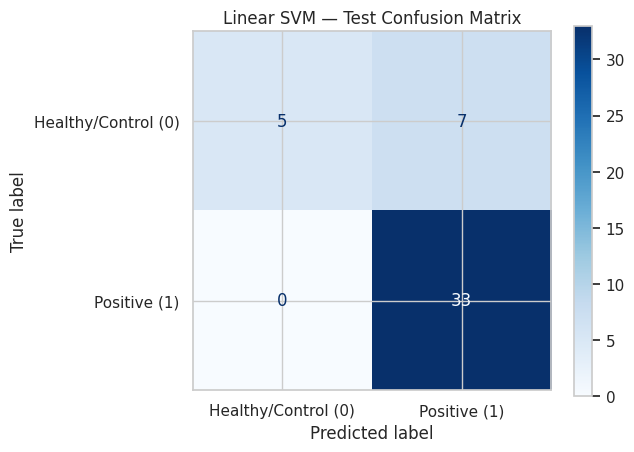

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Calculate metrics
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

test_precision = precision_score(
    y_test, y_test_pred, pos_label=1, zero_division=0
)

test_recall = recall_score(
    y_test, y_test_pred, pos_label=1, zero_division=0
)

test_f1 = f1_score(
    y_test, y_test_pred, pos_label=1, zero_division=0
)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy:  {test_accuracy:.4f}")
print(f"Test Precision (class 1): {test_precision:.4f}")
print(f"Test Recall (class 1):    {test_recall:.4f}")
print(f"Test F1-score (class 1):  {test_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        labels=[0, 1],
        target_names=['Healthy/Control', 'Parkinson’s-positive'],
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Healthy/Control (0)', 'Positive (1)']
)

display.plot(cmap='Blues', values_format='d')
plt.title('Linear SVM — Test Confusion Matrix')
plt.tight_layout()
plt.show()



### 8.2 Evaluation Results and Interpretation

The linear SVM model was evaluated on a subject-wise holdout test set containing 45 records from 7 participant groups.

#### Performance Summary

| Metric | Training | Testing |
|---|---:|---:|
| Accuracy | 92.00% | 84.44% |

Additional test metrics for the Parkinson's-positive class (`status = 1`):

- **Precision:** 82.50%
- **Recall:** 100.00%
- **F1-score:** 90.41%

#### Confusion Matrix Interpretation

The confusion matrix is:

| | Predicted Healthy/Control | Predicted Positive |
|---|---:|---:|
| Actual Healthy/Control | 5 | 7 |
| Actual Positive | 0 | 33 |

The model correctly classified 5 control records and misclassified 7 control records as positive. It correctly classified all 33 positive records in this test set and produced no false negatives.

#### Key Observations

- The test accuracy is 84.44%.
- Positive-class recall is 100% on this particular test set.
- Control-class recall is only 41.67% (5 out of 12 control records).
- The model tends to predict the positive class, which is reflected in the false-positive count.

These results describe this specific holdout split and do not establish clinical performance. The test set is small, and only 12 control records are present. Additional group-based evaluation is needed before drawing broader conclusions.



## 9. Visualizing Class-wise Performance

Overall accuracy can hide differences in how well a classifier identifies each class. In this section, we compare precision, recall, and F1-score for the healthy/control and Parkinson's-positive classes.

This visualization helps reveal whether the model performs consistently across both classes.


,precision,recall,f1-score
Healthy/Control,1.000,0.417,0.588
Parkinson’s-positive,0.825,1.000,0.904


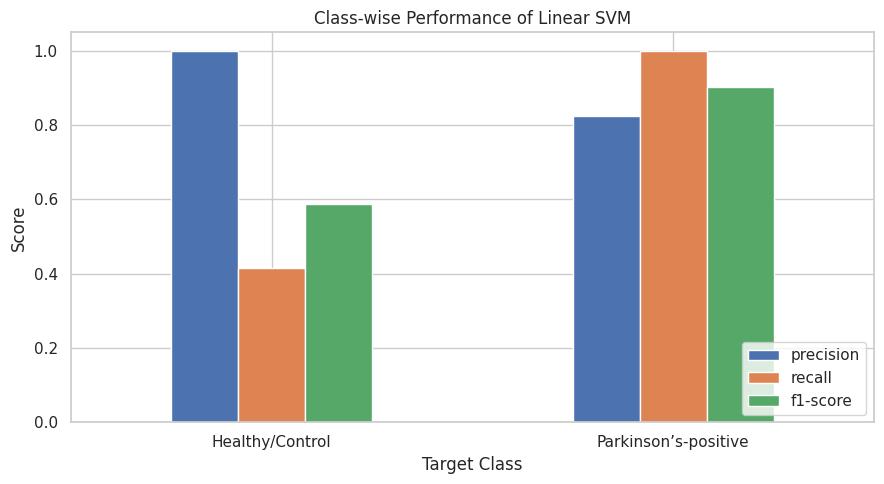

In [ ]:

# Import display again to fix the naming conflict
from IPython.display import display
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
import pandas as pd

# Generate class-wise metrics
report = classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=['Healthy/Control', 'Parkinson’s-positive'],
    output_dict=True,
    zero_division=0
)

# Create a DataFrame containing precision, recall, and F1-score
class_metrics = pd.DataFrame(report).T.loc[
    ['Healthy/Control', 'Parkinson’s-positive'],
    ['precision', 'recall', 'f1-score']
]

# Display the metrics table
display(class_metrics.round(3))

# Plot class-wise metrics
ax = class_metrics.plot(
    kind='bar',
    figsize=(9, 5),
    ylim=(0, 1.05)
)

ax.set_title('Class-wise Performance of Linear SVM')
ax.set_xlabel('Target Class')
ax.set_ylabel('Score')
ax.legend(loc='lower right')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 9. Building a Prediction Function

After training and evaluating the model, we can use it to predict the class of a new sample.

The prediction function will:
1. Accept 22 numerical voice measurements.
2. Arrange the measurements in the same order as the training features.
3. Pass the input to the trained SVM pipeline.
4. Return the predicted class.

Target labels:
- 0: Healthy/Control
- 1: Parkinson's-positive

This prediction is for educational purposes and must not be used as a medical diagnosis.

In [ ]:

def predict_parkinsons(input_data):
    # Get the feature names and their required order
    expected_features = list(X_train.columns)

    # Check that the input contains exactly 22 values
    if len(input_data) != len(expected_features):
        raise ValueError(
            f"Expected {len(expected_features)} features, "
            f"but received {len(input_data)}."
        )

    # Arrange the input values using the training feature order
    input_df = pd.DataFrame(
        [input_data],
        columns=expected_features
    )

    # Predict using the trained pipeline
    prediction = model.predict(input_df)[0]

    if prediction == 0:
        print("Prediction: Healthy/Control (Class 0)")
    else:
        print("Prediction: Parkinson's-positive (Class 1)")

    return prediction


## 10. Testing the Model with a New Sample

We will test the prediction function using a sample containing 22 voice measurements.

The values must follow exactly the same feature order used during model training. The output represents the model's predicted class, not a confirmed medical diagnosis.

In [ ]:

# Sample input from the original project
input_data = (
    139.17300, 179.13900, 76.55600,
    0.00390, 0.00003, 0.00165, 0.00208,
    0.00496, 0.01642, 0.15400, 0.00728,
    0.00932, 0.01797, 0.02184, 0.01041,
    24.88900, 0.430166, 0.665833,
    -5.660217, 0.254989, 2.519422, 0.199889
)

# Run prediction
prediction = predict_parkinsons(input_data)


Prediction: Parkinson's-positive (Class 1)


## 11. Conclusion

In this project, a Support Vector Machine (SVM) classifier with a linear kernel was developed to predict Parkinson's disease status using voice measurement features.

The dataset was inspected for missing values, duplicate records, feature distributions, and class imbalance. The `name` column was excluded from model training because it identifies recordings rather than providing a meaningful numerical measurement. Records from the same participant were kept within the same train or test split to reduce participant-level data leakage.

A machine learning pipeline combining `StandardScaler` and `SVC` was trained and evaluated. The model achieved **84.44% test accuracy** on the selected group-based holdout set. It correctly identified all 33 Parkinson's-positive test records, but it correctly identified only 5 of the 12 Healthy/Control records.

These results show that accuracy alone does not fully describe model performance. Class-wise precision, recall, F1-score, and the confusion matrix provide a more informative evaluation.

The project demonstrates a complete introductory machine learning workflow, including data inspection, exploratory analysis, preprocessing, model training, evaluation, visualization, and prediction on a new sample.

## 12. Limitations and Future Improvements

### Limitations

1. **Small dataset:** The dataset contains only 195 recordings, limiting the reliability and generalizability of the results.
2. **Class imbalance:** The dataset contains more Parkinson's-positive records than Healthy/Control records.
3. **Uneven class performance:** The model achieved 100% recall for the positive class in the test set, but only 41.7% recall for the Healthy/Control class.
4. **Limited test participants:** The test set contains records from only seven participants. The evaluation may therefore be sensitive to the selected split.
5. **No clinical validation:** The model is an educational machine learning experiment and must not be used to diagnose Parkinson's disease.
6. **Limited model comparison:** Only a linear SVM was evaluated in this experiment.

### Future Improvements

- Evaluate the model using repeated group-based holdout splits or group-aware cross-validation.
- Compare linear SVM with RBF SVM, Logistic Regression, Random Forest, and other suitable classifiers.
- Use hyperparameter tuning within a group-aware validation strategy.
- Report confidence intervals or variability across multiple splits.
- Investigate class-specific errors and assess whether the model generalizes to independent participants and external datasets.
- Validate any potential clinical application using appropriate clinical data, expert oversight, and rigorous testing.